<a href="https://colab.research.google.com/github/timothy-shiwprasad/COMP6905_assigment_2/blob/main/Assignment_2_Question_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Question 2 :  A relaible Kanto Communication Network

A)

Objective: Maximize the Probability that every installed link is operational during the storm.

Key Information:

- 8 Verticies (Locations)
- 14 Possible Edges (undirected)
- Each edge has a weight.The weight is the probabilitry that the connection survives during a storm.
- Connect all 8 edges with exactly 7 links installed.

## Graph
$ G = (V,E) $

V = {Pallet,Viridian,Pewter,Cerulean, Vermillion,Saffrom,CDeladon,Fushsia}

E = Set of Candiate Edges.

## Decision Variables

$$
x_e =
\begin{cases}
1, & \text{if link } e \text{ is installed} \\
0, & \text{otherwise}
\end{cases}
$$

## Objective Function

P(Installed Links Operate) =

$$ max_p \prod_{e \in E} p_e$$


## Modification to the Objective Function

The problem is a Maximum spanning tree problem as it requires all verticies with exactly |V| -1  edges (7) and no cycles.


## Converting the objective from Multiplicative to Additive.
Standard Spanning Tree problems are more efficiently solved when the objective has an additive path cost. We will then use `logarthims` to convert our objective to have an additive path cost rather than a multiplicative path cost.

$$ max_p \sum_{e \in E} \log p_e$$

## Converting to a Minimum Cost Problem

Standard Spanning Tree Problems solve a minimum spannnig tree. We will convert the objective to support this. We will use Kruskal's Algorthim to solve the objective function.

$ C_e = -log(p_e)$

Since 0 < pₑ ≤ 1, we get cₑ ≥ 0

## New Objective Function

$$ min_p \sum_{e \in E} C_e$$

Subject to:

$$ \sum_{e \in E} x_e  = 7 $$

$$ \sum_{e \in E(S)} x_e <= |S| -1$$

$$ x_e \in {0,1} $$




















In [ ]:
# Question 2 B
import networkx as nx
import math
from typing import List
import itertools
import matplotlib.pyplot as plt

def minimum_spanning_tree(edges:List[tuple]):
  r"""
  Solve a minimum spanning tree
  """
  G = nx.Graph()
  for u, v, p in edges:
      G.add_edge(u, v, weight=-math.log(p), reliability=p)
  mst = nx.minimum_spanning_tree(G, weight="weight",algorithm="kruskal")
  return mst,G


def generate_graph(mst,G):
  r"""
  Generate the graph solution from
  the minimum spanning tree
  """

  reliability = 1
  for u, v, data in mst.edges(data=True):
      reliability *= data["reliability"]
  pos = {
      "Pewter":(0,3), "Pallet":(0,0), "Viridian":(0,1.5),
      "Cerulean":(2,3), "Saffron":(2,1.5), "Celadon":(1,0.5),
      "Vermilion":(3,2), "Fuchsia":(2.5,0),
  }
  plt.figure(figsize=(9,6))
  nx.draw_networkx_edges(G, pos, edge_color="lightgray", style="dashed")
  nx.draw_networkx_edges(mst, pos, edge_color="tab:blue", width=3)
  nx.draw_networkx_nodes(G, pos, node_color="lightyellow", edgecolors="k", node_size=1800)
  nx.draw_networkx_labels(G, pos, font_size=8)
  nx.draw_networkx_edge_labels(mst, pos, edge_labels={(u,v): d["reliability"] for u,v,d in mst.edges(data=True)})
  plt.title(f"Most reliable spanning tree (R = {reliability:.4f})")
  plt.axis("off"); plt.show()


In [ ]:
# Question 2 B
edges = [
    ("Pallet","Viridian",0.96),
    ("Pallet","Fuchsia",0.76),
    ("Viridian","Pewter",0.93),
    ("Viridian","Celadon",0.84),
    ("Pewter","Cerulean",0.94),
    ("Pewter","Saffron",0.81),
    ("Cerulean","Saffron",0.91),
    ("Cerulean","Vermilion",0.83),
    ("Vermilion","Saffron",0.95),
    ("Vermilion","Fuchsia",0.86),
    ("Saffron","Celadon",0.97),
    ("Saffron","Fuchsia",0.79),
    ("Celadon","Fuchsia",0.92),
    ("Celadon","Vermilion",0.88)
]

mst,G = minimum_spanning_tree(edges)

reliability = 1
for u, v, data in mst.edges(data=True):
    reliability *= data["reliability"]

print("Selected Links:")
for u, v in mst.edges():
    print(f"{u} - {v}")

print("\nNetwork Reliability =", reliability)

Selected Links:
Pallet - Viridian
Viridian - Pewter
Fuchsia - Celadon
Pewter - Cerulean
Celadon - Saffron
Cerulean - Saffron
Saffron - Vermilion

Network Reliability = 0.6474505355136


# Question 2 B

The Network reliablity is : 0.65 (65%)

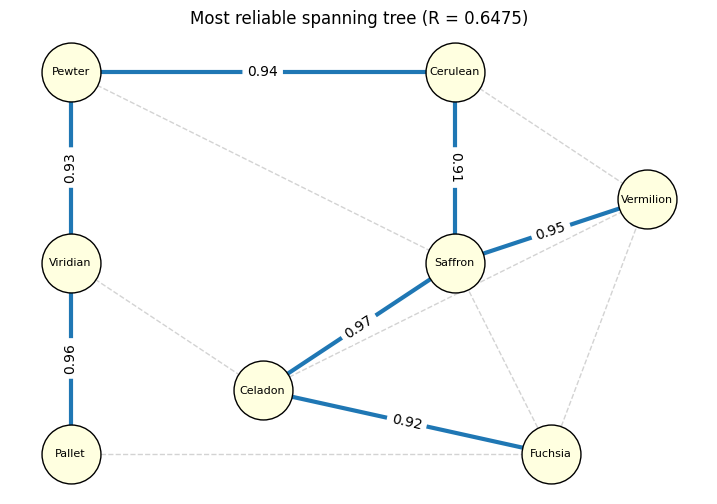

In [ ]:
# Question 2 B
generate_graph(mst,G)

In [ ]:
# Question 2 (C)

# Make the change in operating probability of Saffron to Celadon tp 0.75

edges = [
    ("Pallet","Viridian",0.96),
    ("Pallet","Fuchsia",0.76),
    ("Viridian","Pewter",0.93),
    ("Viridian","Celadon",0.84),
    ("Pewter","Cerulean",0.94),
    ("Pewter","Saffron",0.81),
    ("Cerulean","Saffron",0.91),
    ("Cerulean","Vermilion",0.83),
    ("Vermilion","Saffron",0.95),
    ("Vermilion","Fuchsia",0.86),
    ("Saffron","Celadon",0.75),
    ("Saffron","Fuchsia",0.79),
    ("Celadon","Fuchsia",0.92),
    ("Celadon","Vermilion",0.88)
]

mst_c,G_c= minimum_spanning_tree(edges)

reliability = 1
for u, v, data in mst_c.edges(data=True):
    reliability *= data["reliability"]

print("Selected Links:")
for u, v in mst_c.edges():
    print(f"{u} - {v}")

print("\nNetwork Reliability =", reliability)


Selected Links:
Pallet - Viridian
Viridian - Pewter
Fuchsia - Celadon
Pewter - Cerulean
Celadon - Vermilion
Cerulean - Saffron
Saffron - Vermilion

Network Reliability = 0.5873778054144


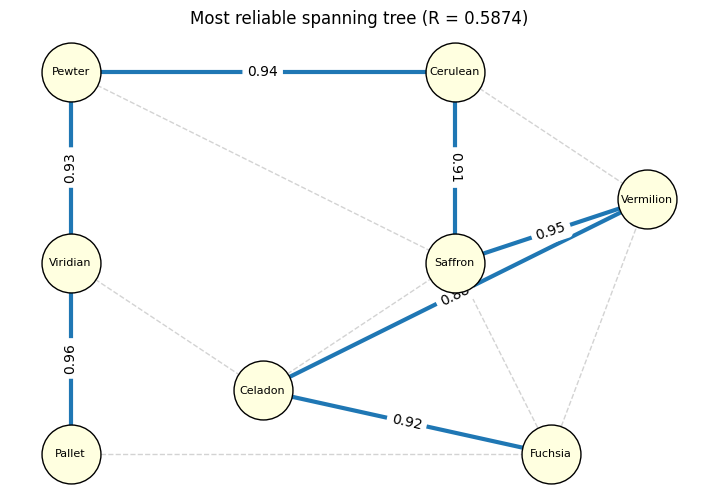

In [ ]:
generate_graph(mst_c,G_c)

# Question 2 C

The new Network Reliability : 0.59 (59%)

The Graph maintains most of it structure starting from Pallet town up to Saffron. We lose the direct connection to Celadon from Saffron and the Network now connects to Celadon through Vermillion.

We experience a drop of roughly 0.06 (6%) in reliability.